# NLopt Optimizer Tutorial

This tutorial demonstrates how to use the `libskit.Optimizer` class to fit LTE model parameters to measured or synthetic spectra.  The optimizer wraps [NLopt](https://nlopt.readthedocs.io/) and works with **any** plasma model type (`LTEModel`, `LTELayers`, `LTETimeIntegrated`, …).

We showcase:
- **L-BFGS** – a fast gradient-based method (uses autodiff gradients)
- **Nelder-Mead** – a gradient-free simplex method
- **Convergence analysis** – multi-start optimization with Latin Hypercube Sampling

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import libskit
import nlopt

# Enable interactive plots
%matplotlib widget

Loading databases from: ../databases
✓ Databases loaded successfully!
  Lines: 2563 lines across 68 ions
  Ionization energies: 5847 entries
  Levels: 5331 ions


## 1. Create True Model and Synthetic Data

Create a "true" plasma model with known parameters that we will try to recover through optimization.

In [ ]:
# "True" plasma parameters (what we want to recover)
true_element_ratio = {
    "Na": 0.5,
    "Mn": 0.25,
    "Mg": 0.20,
    "Ca": 0.05,
}

true_model = libskit.LTEModel(
    true_element_ratio,
    8300.0,   # temperature [K]
    2.3e23,   # electron density [m⁻³]
    3e-4      # plasma length [m]
)

# Generate a synthetic "measured" spectrum
wavelengths = np.arange(250, 900, 0.1)
instrument = libskit.GenericSpectrometer(0.05, 0.001)
true_spectrum = instrument.calculate_spectrum(wavelengths, true_model)
measured_spectrum = libskit.Spectrum(wavelengths, true_spectrum)

# Visualise the target
plt.figure(figsize=(12, 5))
plt.plot(wavelengths, true_spectrum.real, 'b-', linewidth=0.8)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Intensity')
plt.title('Target Spectrum')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Create Initial Guess and Experiment

Create an initial parameter guess that is intentionally off, then set up the `Experiment` for optimization.

In [ ]:
guess_model = libskit.LTEModel(
    {"Na": 0.25, "Mn": 0.25, "Mg": 0.25, "Ca": 0.25},
    10000.0,   # temperature  (true: 8 300)
    1e23,      # n_e          (true: 2.3e23)
    1e-4,      # length       (true: 3e-4)
)

experiment = libskit.Experiment(
    libskit.LossType.IntensityWeightedLoss,
    guess_model,
    instrument,
    measured_spectrum
)

print("Initial guess:")
for name in guess_model.get_parameter_names():
    print(f"  {name:20s} = {guess_model.get_parameter(name):.4g}")

## 3. L-BFGS Optimization (gradient-based)

L-BFGS uses the model's autodiff gradients and typically converges in very few iterations.

In [4]:
optimizer = libskit.Optimizer(experiment)
result_lbfgs = optimizer.optimize(
    algorithm=nlopt.LD_LBFGS,
    max_eval=200,
    verbose=True,
)

# Summary
print(f"\nAlgorithm : {result_lbfgs['algorithm']}")
print(f"Status    : {result_lbfgs['status']}")
print(f"Evals     : {result_lbfgs['n_evaluations']}")
print(f"Final loss: {result_lbfgs['final_loss']:.4e}")

print("\nRecovered parameters vs truth:")
for name in optimizer.param_names:
    true_val = true_model.get_parameter(name)
    fit_val  = result_lbfgs['history'][name][-1]
    print(f"  {name:20s}  true={true_val:.4g}   fit={fit_val:.4g}")

Optimizer: Limited-memory BFGS (L-BFGS) (local, derivative-based)
Parameters (7): ['temperature', 'electron_density', 'length', 'Ca', 'Mg', 'Mn', 'Na']
Max evaluations: 200
Iter    1: Loss=4.8892e+02  temperature=10000  electron_density=1.00e+23  length=1.000e-04  Ca=0.2500  Mg=0.2500  Mn=0.2500  Na=0.2500
Iter    2: Loss=4.1272e+02  temperature=5000  electron_density=1.08e+23  length=1.034e-04  Ca=0.2626  Mg=0.2343  Mn=0.2637  Na=0.2394
Iter    3: Loss=4.0584e+02  temperature=9253  electron_density=1.02e+23  length=1.008e-04  Ca=0.2497  Mg=0.2472  Mn=0.2540  Na=0.2490
Iter   11: Loss=1.4148e+02  temperature=6834  electron_density=1.24e+23  length=1.108e-04  Ca=0.0000  Mg=0.5029  Mn=0.3776  Na=0.1194
Iter   21: Loss=1.4166e+02  temperature=6808  electron_density=1.22e+23  length=1.102e-04  Ca=0.0000  Mg=0.4942  Mn=0.3856  Na=0.1202
Iter   31: Loss=3.2177e+01  temperature=6738  electron_density=1.24e+23  length=1.106e-04  Ca=0.0416  Mg=0.4540  Mn=0.3656  Na=0.1389
Iter   41: Loss=6.4221

## 4. Visualise L-BFGS Results

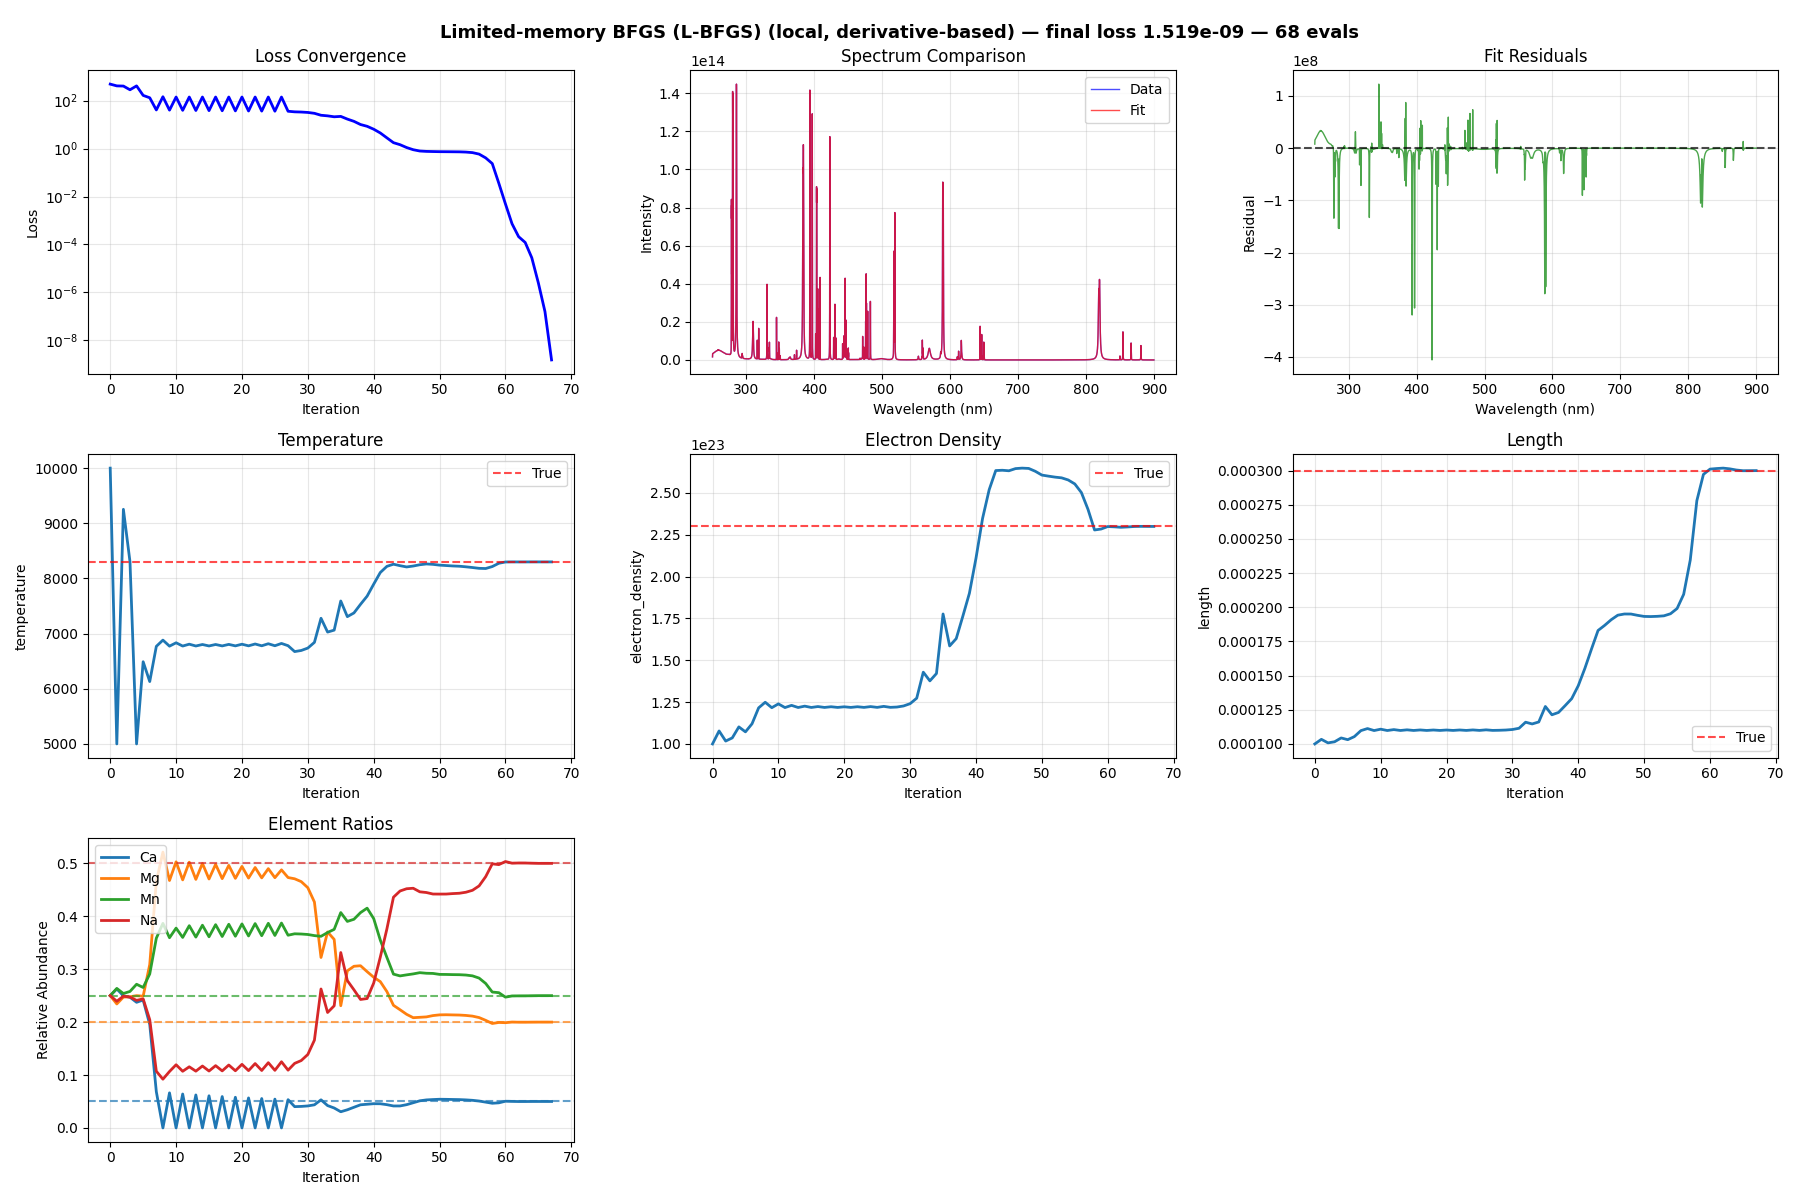

In [5]:
fig, axes = libskit.visualization.plot_optimization_results(
    result_lbfgs,
    experiment,
    true_model=true_model,
    figsize=(18, 12),
)
plt.show()

## 5. Nelder-Mead Optimization (gradient-free)

Nelder-Mead does not need gradients, but needs more evaluations.  Let's reset the initial guess and run it.

In [ ]:
# Reset the guess model back to the initial parameters
guess_model_nm = libskit.LTEModel(
    {"Na": 0.25, "Mn": 0.25, "Mg": 0.25, "Ca": 0.25},
    10000.0, 1e23, 1e-4
)
experiment_nm = libskit.Experiment(
    libskit.LossType.IntensityWeightedLoss, guess_model_nm, instrument, measured_spectrum
)

optimizer_nm = libskit.Optimizer(experiment_nm)
result_nm = optimizer_nm.optimize(
    algorithm=nlopt.LN_NELDERMEAD,
    max_eval=1000,
    verbose=True,
)

print(f"\nAlgorithm : {result_nm['algorithm']}")
print(f"Status    : {result_nm['status']}")
print(f"Evals     : {result_nm['n_evaluations']}")
print(f"Final loss: {result_nm['final_loss']:.4e}")

print("\nRecovered parameters vs truth:")
for name in optimizer_nm.param_names:
    true_val = true_model.get_parameter(name)
    fit_val  = result_nm['history'][name][-1]
    print(f"  {name:20s}  true={true_val:.4g}   fit={fit_val:.4g}")

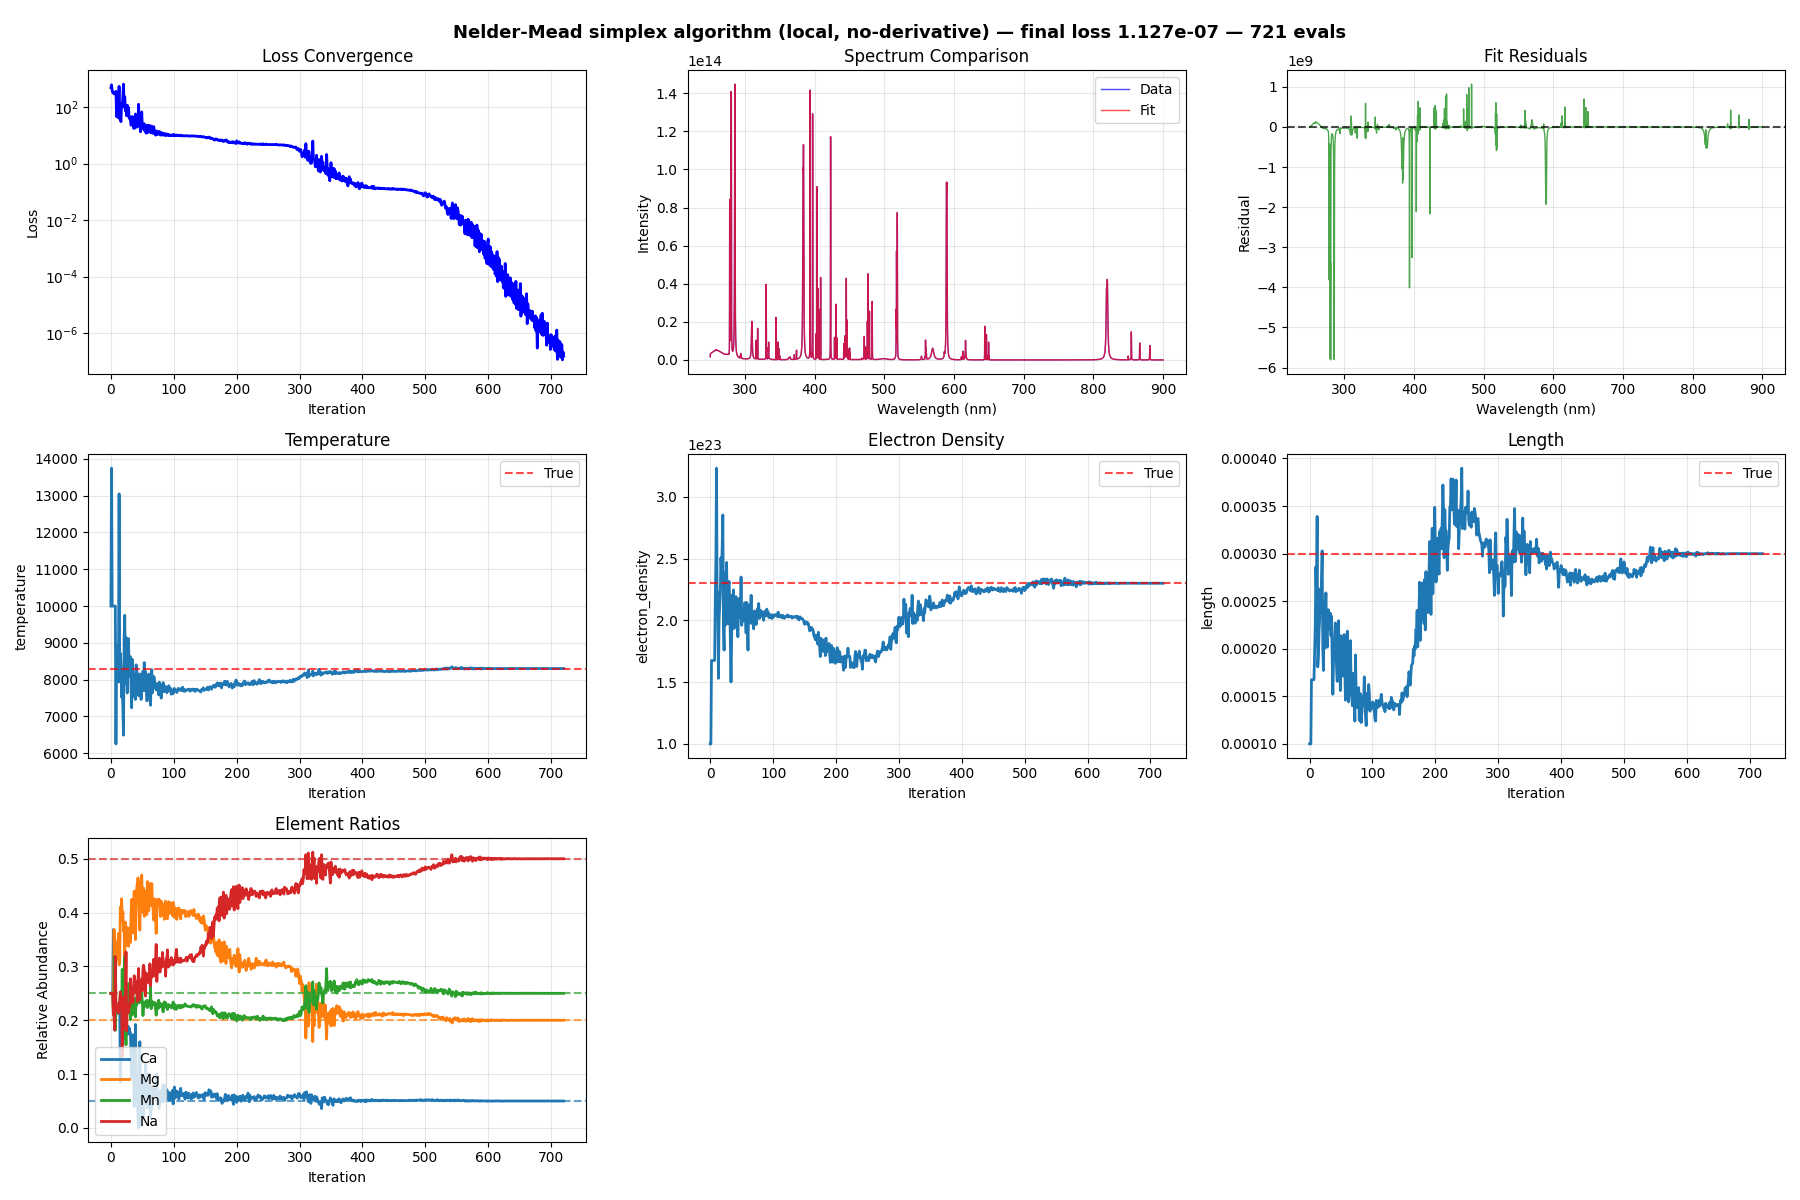

In [7]:
fig, axes = libskit.visualization.plot_optimization_results(
    result_nm,
    experiment_nm,
    true_model=true_model,
    figsize=(18, 12),
)
plt.show()